In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [ ]:
rfm = pd.read_csv('/content/drive/MyDrive/segmentation_project/rfm.csv')

In [ ]:
rfm_scaled = pd.read_csv('/content/drive/MyDrive/segmentation_project/rfm_scaled.csv')

In [ ]:
features = ['Recency', 'Frequency', 'Monetary']
X = rfm_scaled[features]
print(X.shape)

(5878, 3)


In [ ]:
k_values =[]
inertia_values = []
silhouette_values = []

for k in range(2,11):
  kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
  labels = kmeans.fit_predict(X)

  k_values.append(k)
  inertia_values.append(kmeans.inertia_)
  silhouette_values.append(silhouette_score(X,labels))





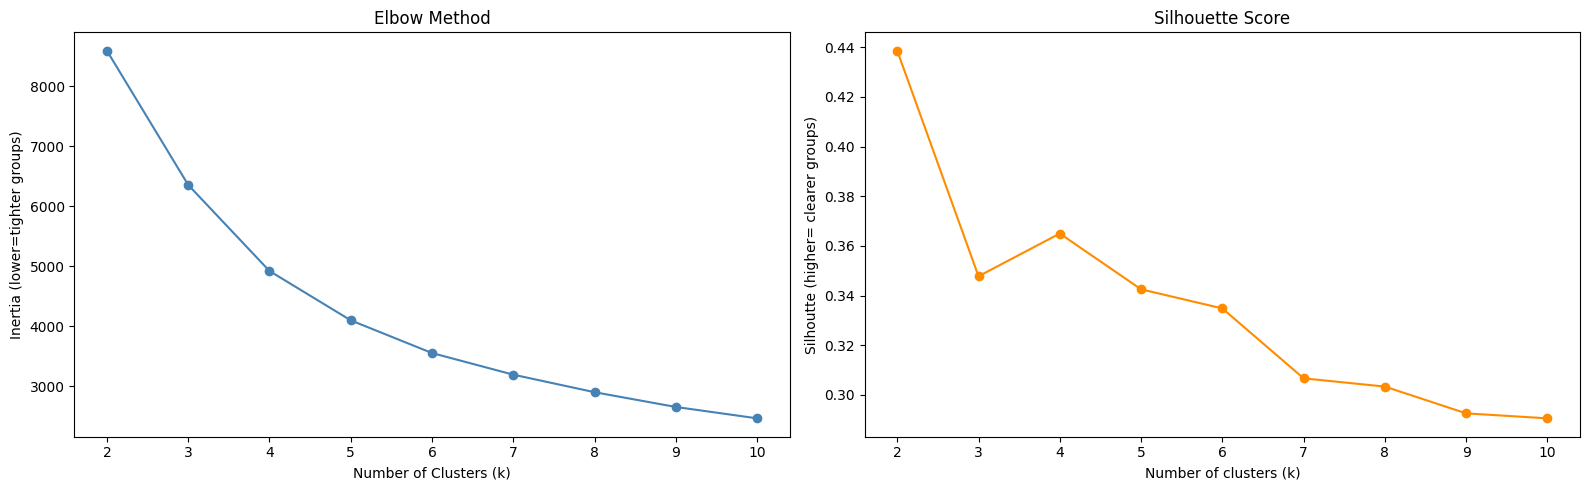

In [ ]:
fig, axes = plt.subplots(1,2, figsize=(16,5))
axes[0].plot(k_values, inertia_values, marker='o', color='steelblue')
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia (lower=tighter groups)')

axes[1].plot(k_values, silhouette_values, marker='o', color='darkorange')
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Number of clusters (k)')
axes[1].set_ylabel('Silhoutte (higher= clearer groups)')

plt.tight_layout()
plt.show()

In [ ]:
scores = pd.DataFrame({'k': k_values, 'Inertia': inertia_values, 'Silhoutte': silhouette_values}).round(3)
scores

,k,Inertia,Silhoutte
0,2,8588.985,0.439
1,3,6354.343,0.348
2,4,4921.233,0.365
3,5,4099.106,0.342
4,6,3554.696,0.335
5,7,3194.501,0.307
6,8,2902.434,0.303
7,9,2656.562,0.293
8,10,2467.378,0.291


In [ ]:
for k in [3,4,5]:
  kmeans =KMeans(n_clusters=k, n_init=10, random_state=42)

  temp = rfm.copy()
  temp['Cluster'] = kmeans.fit_predict(X)

  profile = temp.groupby('Cluster').agg(
      Recency = ('Recency', 'mean'),
      Frequency = ('Frequency', 'mean'),
      Monetary = ('Monetary', 'mean'),
      Customers = ('Customer ID', 'count')
  ).round(0)

  print("=========== k =", k, "===========")
  print(profile)
  print()



=========== k = 3 ===========
         Recency  Frequency  Monetary  Customers
Cluster                                         
0          374.0        2.0     397.0       2402
1           33.0       19.0   10667.0       1216
2          108.0        4.0    1527.0       2260

=========== k = 4 ===========
         Recency  Frequency  Monetary  Customers
Cluster                                         
0          395.0        1.0     317.0       1973
1           28.0        3.0     857.0       1250
2           28.0       19.0   10731.0       1196
3          230.0        5.0    1949.0       1459

=========== k = 5 ===========
         Recency  Frequency  Monetary  Customers
Cluster                                         
0           18.0       33.0   20818.0        458
1          294.0        4.0    1386.0       1363
2           49.0        9.0    3674.0       1294
3           32.0        3.0     683.0       1143
4          416.0        1.0     258.0       1620



In [ ]:
kmeans = KMeans(n_clusters=5, n_init=10, random_state=42)
check = rfm.copy()
check['Cluster'] = kmeans.fit_predict(X)
summary = check.groupby('Cluster').agg(
    Customers=('Customer ID', 'count'),
    Revenue=('Monetary', 'sum'))
summary['% Customers'] = (summary['Customers']/ summary['Customers'].sum()*100).round(2)
summary['% Revenue'] = (summary['Revenue']/ summary['Revenue'].sum()*100).round(2)
summary

,Customers,Revenue,% Customers,% Revenue
Cluster,,,,
0,458,9534456.884,7.79,54.88
1,1363,1888917.713,23.19,10.87
2,1294,4753522.538,22.01,27.36
3,1143,780150.982,19.45,4.49
4,1620,417756.151,27.56,2.40


In [ ]:
final_kmeans = KMeans(n_clusters=5, n_init=10, random_state=42)
rfm['Cluster'] = final_kmeans.fit_predict(X)
rfm.head()

,Customer ID,Recency,Frequency,Monetary,Cluster
0,12346,326,12,77556.46,2
1,12347,2,8,4921.53,2
2,12348,75,5,2019.40,2
3,12349,19,4,4428.69,2
4,12350,310,1,334.40,4


In [ ]:
profile = rfm.groupby('Cluster').agg(
    Recency = ('Recency', 'mean'),
    Frequency = ('Frequency', 'mean'),
    Monetary = ('Monetary', 'mean'),
    Customers = ('Customer ID', 'count')
    ).round(0)
profile


,Recency,Frequency,Monetary,Customers
Cluster,,,,
0,18.0,33.0,20818.0,458
1,294.0,4.0,1386.0,1363
2,49.0,9.0,3674.0,1294
3,32.0,3.0,683.0,1143
4,416.0,1.0,258.0,1620


In [ ]:
segment_names = {
    0: 'VIP Champions',
    1: 'At Risk',
    2: 'New / Promising',
    3: 'Need Attention',
    4: 'Lost'

}
rfm['Segment'] = rfm['Cluster'].map(segment_names)
rfm.head()

,Customer ID,Recency,Frequency,Monetary,Cluster,Segement,Segment
0,12346,326,12,77556.46,2,New / Promising,New / Promising
1,12347,2,8,4921.53,2,New / Promising,New / Promising
2,12348,75,5,2019.40,2,New / Promising,New / Promising
3,12349,19,4,4428.69,2,New / Promising,New / Promising
4,12350,310,1,334.40,4,Lost,Lost


In [ ]:
segment_order = ['VIP Champions','New / Promising', 'Need Attention','At Risk', 'Lost']

summary = rfm.groupby('Segment').agg(
    Customers=('Customer ID', 'count'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Spend=('Monetary', 'mean'),
    Total_Revenue=('Monetary', 'sum')
)

summary['% Customers'] = summary['Customers'] / summary['Customers'].sum() * 100
summary['% Revenue'] = summary['Total_Revenue'] / summary['Total_Revenue'].sum() * 100

# Put the rows in our chosen order and round the numbers
summary = summary.loc[segment_order].round(1)

summary

,Customers,Avg_Recency,Avg_Frequency,Avg_Spend,Total_Revenue,% Customers,% Revenue
Segment,,,,,,,
VIP Champions,458,18.1,32.9,20817.6,9534456.9,7.8,54.9
New / Promising,1294,48.9,9.1,3673.5,4753522.5,22.0,27.4
Need Attention,1143,32.5,2.5,682.5,780151.0,19.4,4.5
At Risk,1363,293.7,3.8,1385.9,1888917.7,23.2,10.9
Lost,1620,416.4,1.2,257.9,417756.2,27.6,2.4


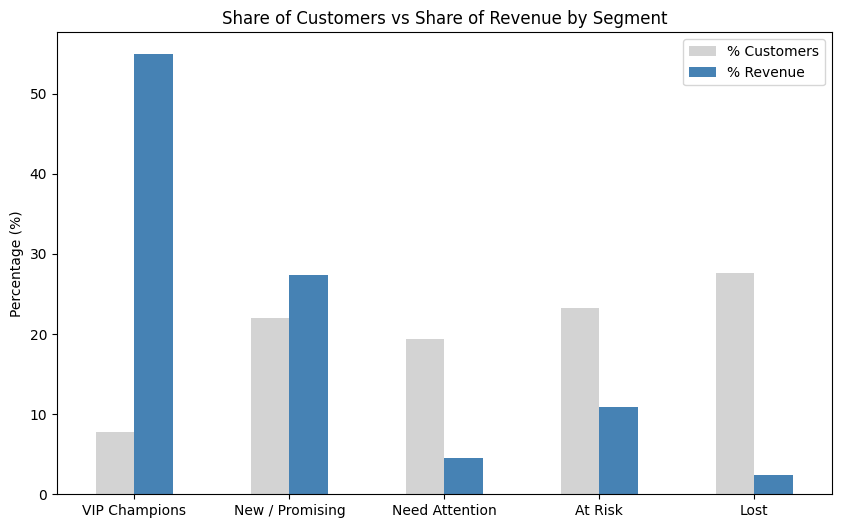

In [ ]:
ax = summary[['% Customers', '% Revenue']].plot(
    kind='bar',
    figsize=(10, 6),
    color=['lightgray', 'steelblue']
)

plt.title('Share of Customers vs Share of Revenue by Segment')
plt.ylabel('Percentage (%)')
plt.xlabel('')
plt.xticks(rotation=0)


plt.show()

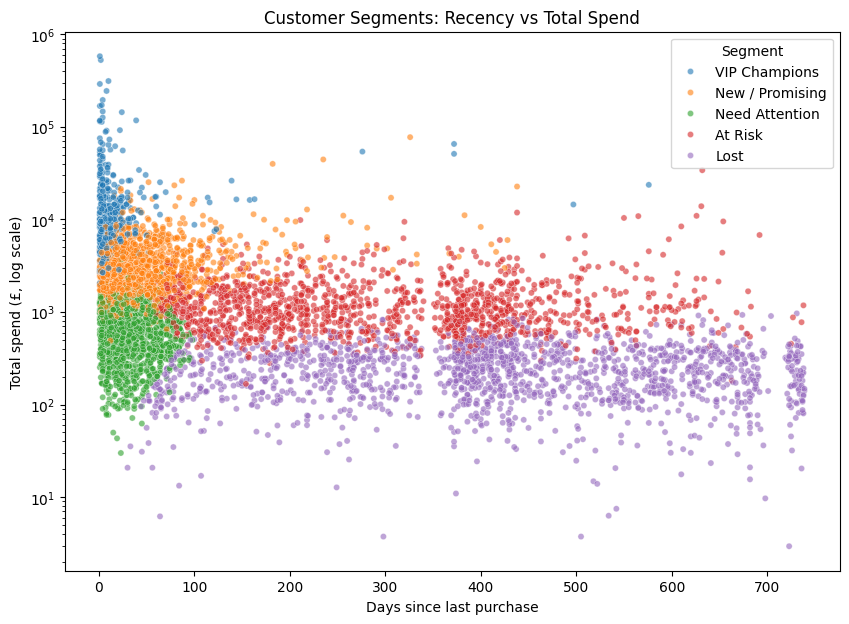

In [ ]:
import seaborn as sns

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=rfm,
    x='Recency',
    y='Monetary',
    hue='Segment',
    hue_order=segment_order,
    alpha=0.6,
    s=20  )

plt.yscale('log')
plt.title('Customer Segments: Recency vs Total Spend')
plt.xlabel('Days since last purchase')
plt.ylabel('Total spend (£, log scale)')

plt.show()

In [ ]:
actions = {
    'VIP Champions': 'Dedicated account manager, early access to new stock, loyalty rewards',
    'Loyal': 'Volume discounts and cross-selling to grow them into VIPs',
    'New / Promising': 'Welcome series and a second-order incentive to build the habit',
    'At Risk': 'Personal win-back contact and a time-limited offer',
    'Lost': 'Low-cost automated email only; do not spend heavily'
}

rfm['Action'] = rfm['Segment'].map(actions)

pd.DataFrame({'Action': actions})
rfm.head()

,Customer ID,Recency,Frequency,Monetary,Cluster,Segement,Segment,Action
0,12346,326,12,77556.46,2,New / Promising,New / Promising,Welcome series and a second-order incentive to...
1,12347,2,8,4921.53,2,New / Promising,New / Promising,Welcome series and a second-order incentive to...
2,12348,75,5,2019.40,2,New / Promising,New / Promising,Welcome series and a second-order incentive to...
3,12349,19,4,4428.69,2,New / Promising,New / Promising,Welcome series and a second-order incentive to...
4,12350,310,1,334.40,4,Lost,Lost,Low-cost automated email only; do not spend he...


In [ ]:
rfm.to_csv('/content/drive/MyDrive/segmentation_project/customer_segments.csv', index=False)

In [ ]:
rfm.head()

,Customer ID,Recency,Frequency,Monetary,Cluster,Segement,Segment,Action
0,12346,326,12,77556.46,2,New / Promising,New / Promising,Welcome series and a second-order incentive to...
1,12347,2,8,4921.53,2,New / Promising,New / Promising,Welcome series and a second-order incentive to...
2,12348,75,5,2019.40,2,New / Promising,New / Promising,Welcome series and a second-order incentive to...
3,12349,19,4,4428.69,2,New / Promising,New / Promising,Welcome series and a second-order incentive to...
4,12350,310,1,334.40,4,Lost,Lost,Low-cost automated email only; do not spend he...
